Technological Institute of the Philippines | Quezon City - Computer Engineering
--- | ---
Course Code: | CPE 027
Code Title: | Digital Signal Processing and Application
1st Semester | AY 2026-2027
<u>**Laboratory Activity 9** | **Discrete Fourier Transform Properties**
**Name** | Adrian Justin Bulambao
**Section** | CPE41S1
**Date Performed**: | October 10, 2026
**Date Submitted**: | October 10, 2026
**Instructor**: | Engr. Leah Belaya

<hr>


<H1><b>Part 1

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Sampling parameters
fs = 20000
duration = 0.01
N = int(fs * duration)

t = np.arange(N) / fs

# Signal parameters
frequencies = [1200, 3500, 5000, 8500]
amplitudes = [10, 15, 8, 12]
phases = [0, 0, 0, 0]  # radians

# Create the four sinusoidal signals
signals = [
    A * np.sin(2 * np.pi * f * t + phase)
    for f, A, phase in zip(frequencies, amplitudes, phases)
]

# DFT basis functions
n = np.arange(N)
k = np.arange(N)

basis = np.exp(
    -1j * 2 * np.pi * np.outer(k, n) / N
)

def calculate_dft(signal):
    return basis @ signal

# Calculate DFT for each individual signal
dfts = [calculate_dft(signal) for signal in signals]

# Extract real, imaginary, magnitude, and phase arrays
real_parts = [np.real(X) for X in dfts]
imag_parts = [np.imag(X) for X in dfts]
magnitudes = [np.abs(X) for X in dfts]
phases_dft = [np.angle(X) for X in dfts]

# Frequency bins for plotting
freq_bins = np.fft.fftfreq(N, d=1/fs)

# Sort frequency bins from negative to positive
order = np.argsort(freq_bins)

1. Create and plot different signals with the following frequencies, amplitudes, and phase angle:

    a.1200 Hz, 10 units,

    b. 3500 Hz, 15, units,

    c. 5000 Hz, 8 units,

    d. 8500 Hz, 12 units,

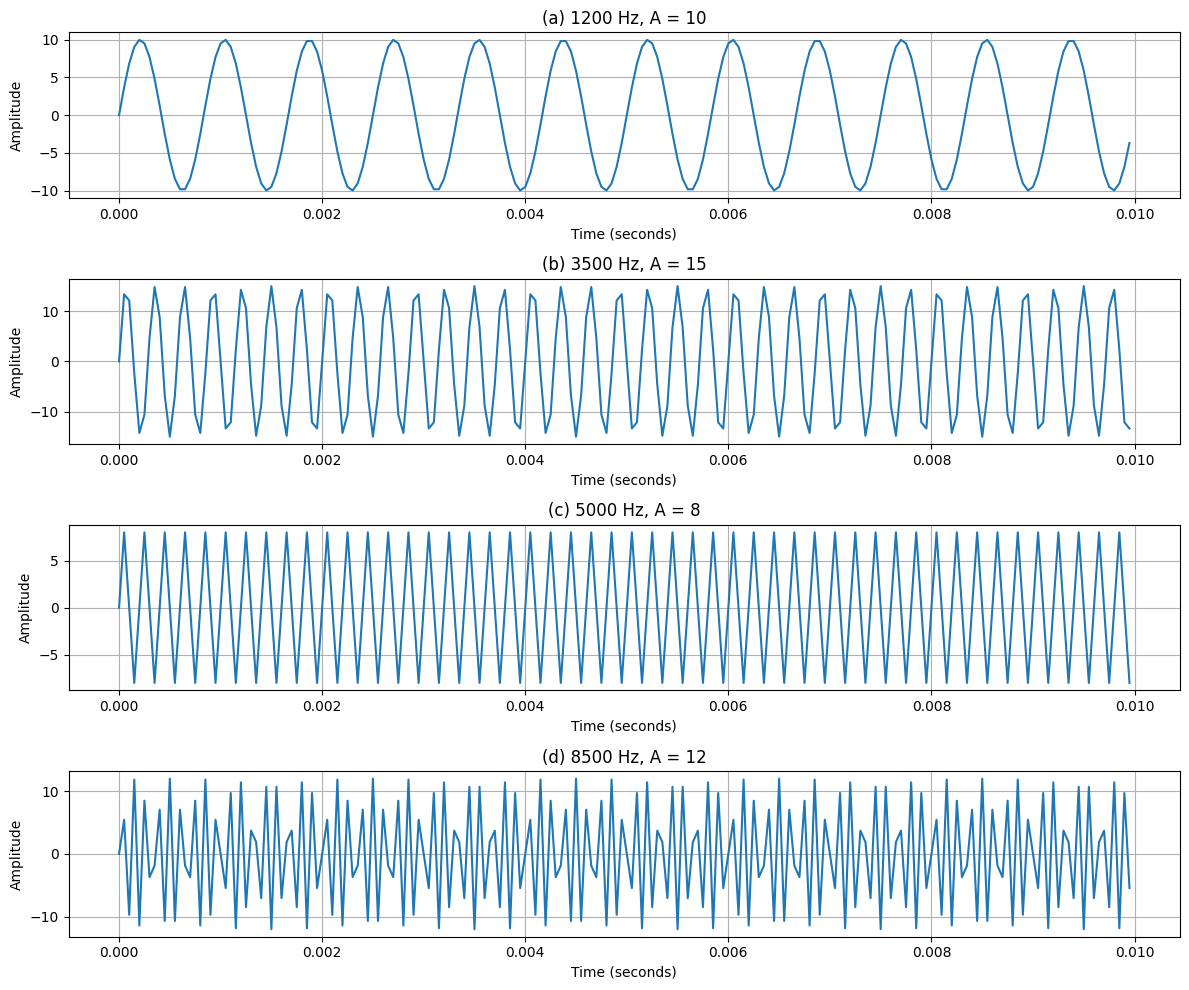

In [ ]:
labels = ["(a) 1200 Hz, A = 10",
          "(b) 3500 Hz, A = 15",
          "(c) 5000 Hz, A = 8",
          "(d) 8500 Hz, A = 12"]

fig, axes = plt.subplots(4, 1, figsize=(12, 10))

for i, ax in enumerate(axes):
    ax.plot(t, signals[i])
    ax.set_title(labels[i])
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()
plt.show()


2. Now, perform Discrete Fourier Transform calculation on each 4 signals using the basis functions. Plot their individual Re X[k] and Im X[k] values.

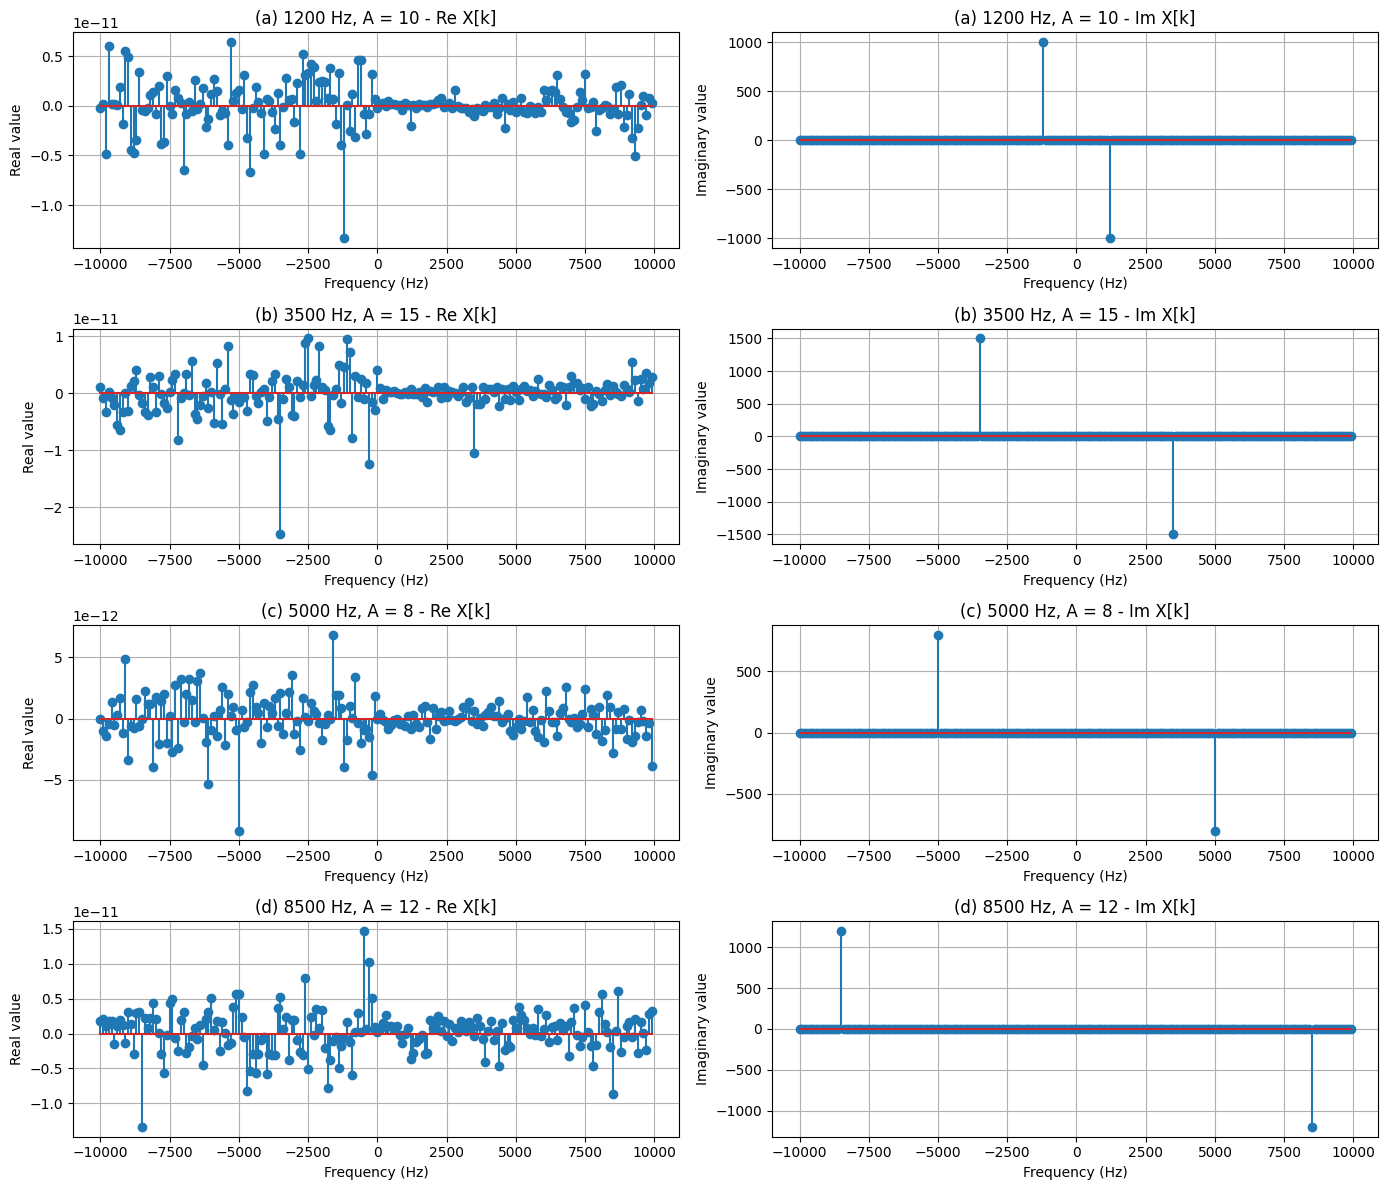

In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(14, 12))

for i in range(4):
    axes[i, 0].stem(freq_bins[order], real_parts[i][order])
    axes[i, 0].set_title(f"{labels[i]} - Re X[k]")
    axes[i, 0].set_xlabel("Frequency (Hz)")
    axes[i, 0].set_ylabel("Real value")
    axes[i, 0].grid(True)

    axes[i, 1].stem(freq_bins[order], imag_parts[i][order])
    axes[i, 1].set_title(f"{labels[i]} - Im X[k]")
    axes[i, 1].set_xlabel("Frequency (Hz)")
    axes[i, 1].set_ylabel("Imaginary value")
    axes[i, 1].grid(True)

plt.tight_layout()
plt.show()

3. Compute the Mag X[k] and Phase X[k] of each signals as well.


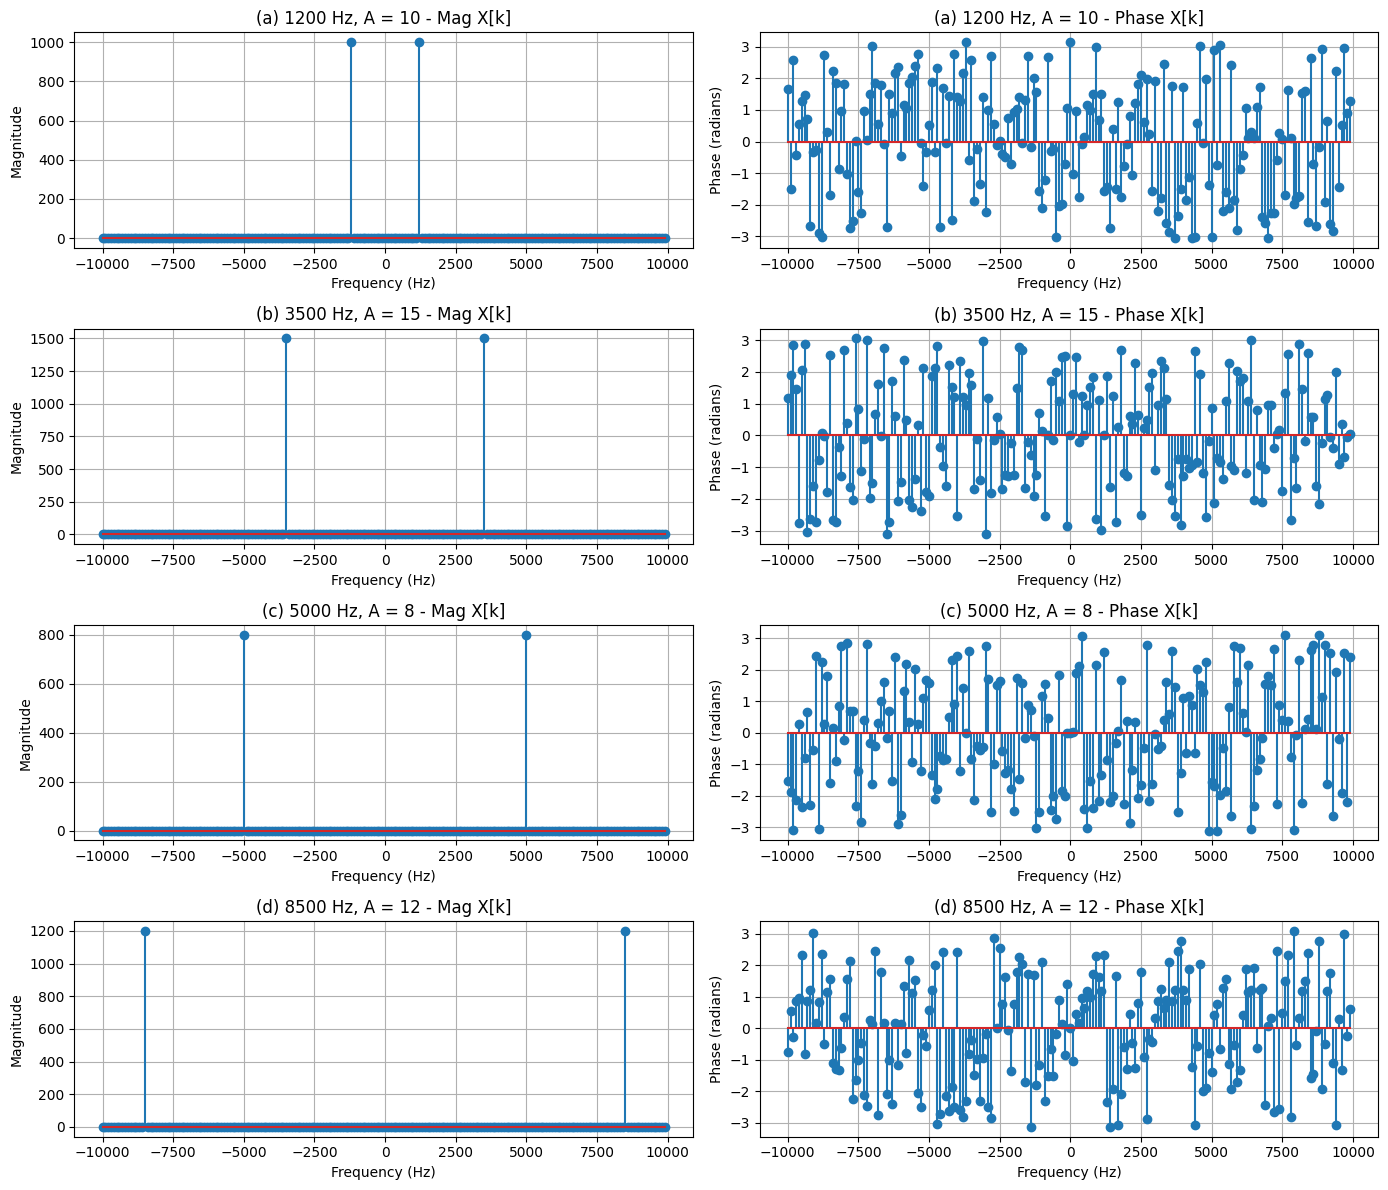

In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(14, 12))

for i in range(4):
    axes[i, 0].stem(freq_bins[order], magnitudes[i][order])
    axes[i, 0].set_title(f"{labels[i]} - Mag X[k]")
    axes[i, 0].set_xlabel("Frequency (Hz)")
    axes[i, 0].set_ylabel("Magnitude")
    axes[i, 0].grid(True)

    axes[i, 1].stem(freq_bins[order], phases_dft[i][order])
    axes[i, 1].set_title(f"{labels[i]} - Phase X[k]")
    axes[i, 1].set_xlabel("Frequency (Hz)")
    axes[i, 1].set_ylabel("Phase (radians)")
    axes[i, 1].grid(True)

plt.tight_layout()
plt.show()

4. Then add all 4 Re X[k] arrays and add all 4 Im X[k] arrays. Plot the resultant graph.


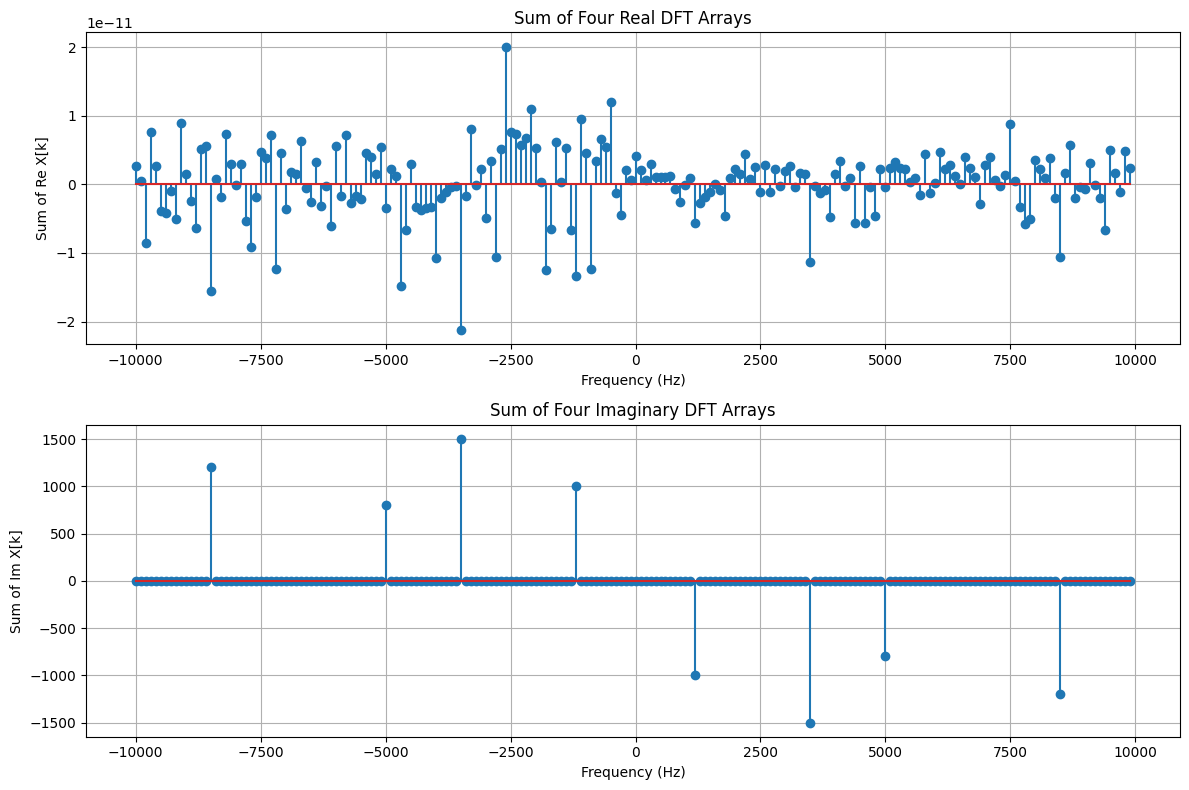

In [ ]:
sum_real = np.sum(real_parts, axis=0)
sum_imag = np.sum(imag_parts, axis=0)

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].stem(freq_bins[order], sum_real[order])
axes[0].set_title("Sum of Four Real DFT Arrays")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Sum of Re X[k]")
axes[0].grid(True)

axes[1].stem(freq_bins[order], sum_imag[order])
axes[1].set_title("Sum of Four Imaginary DFT Arrays")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Sum of Im X[k]")
axes[1].grid(True)

plt.tight_layout()
plt.show()

5. Then add all 4 Mag X[k] arrays and add all 4 Phase X[k] arrays. Plot the resultant graph.


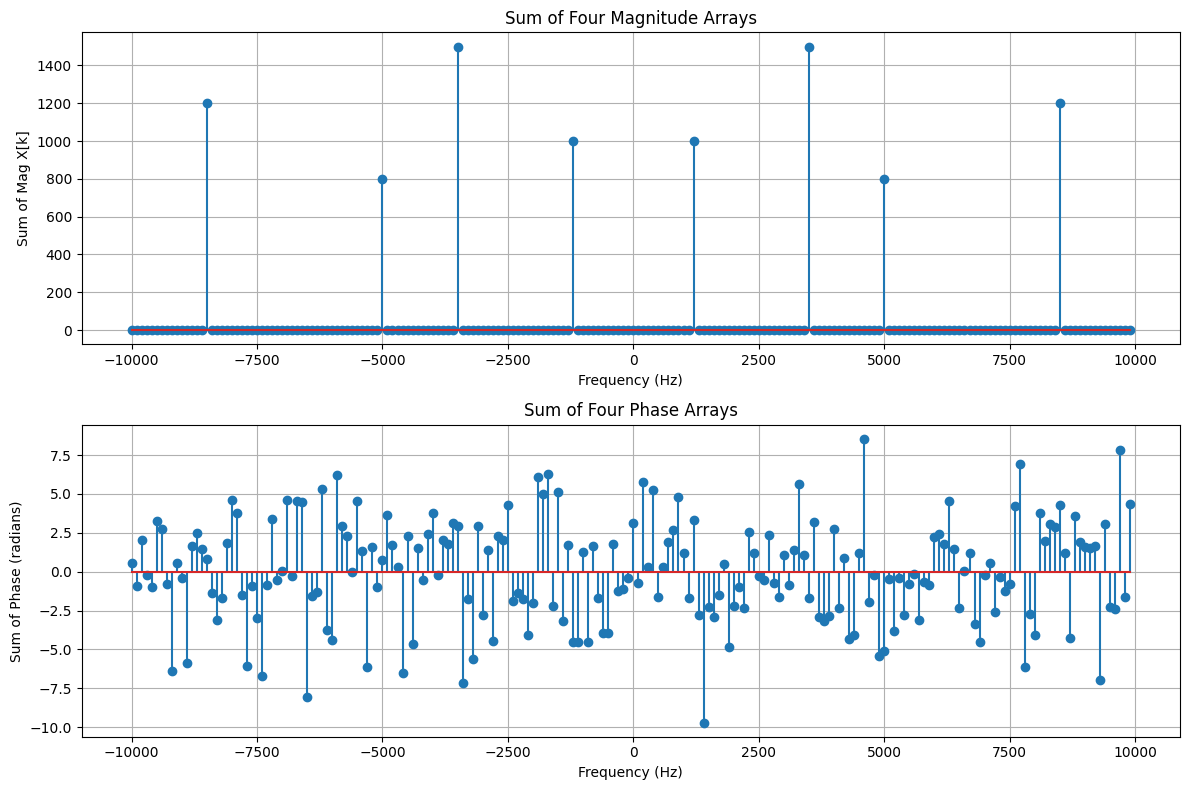

In [ ]:
sum_magnitude = np.sum(magnitudes, axis=0)
sum_phase = np.sum(phases_dft, axis=0)

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].stem(freq_bins[order], sum_magnitude[order])
axes[0].set_title("Sum of Four Magnitude Arrays")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Sum of Mag X[k]")
axes[0].grid(True)

axes[1].stem(freq_bins[order], sum_phase[order])
axes[1].set_title("Sum of Four Phase Arrays")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Sum of Phase (radians)")
axes[1].grid(True)

plt.tight_layout()
plt.show()

<H1><b>Part 2

1. Combine the 4 created signals you created in Part 1. Then, plot it.


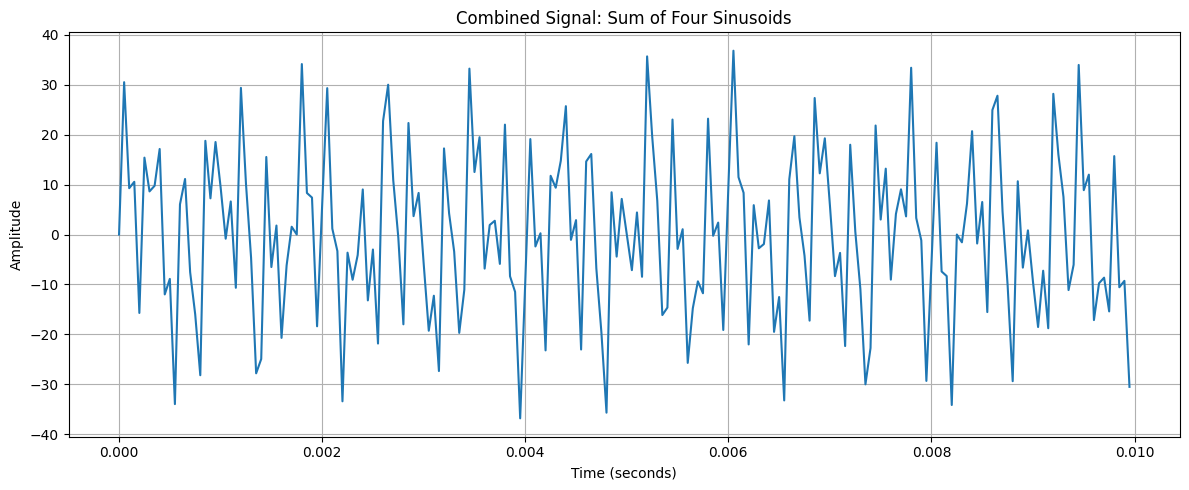

In [ ]:
combined_signal = np.sum(signals, axis=0)

plt.figure(figsize=(12, 5))
plt.plot(t, combined_signal)

plt.title("Combined Signal: Sum of Four Sinusoids")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.tight_layout()
plt.show()

2. Perform Discrete Fourier Transform calculation on combined signal using the basis functions. Plot their Re X[k] and Im X[k] values.


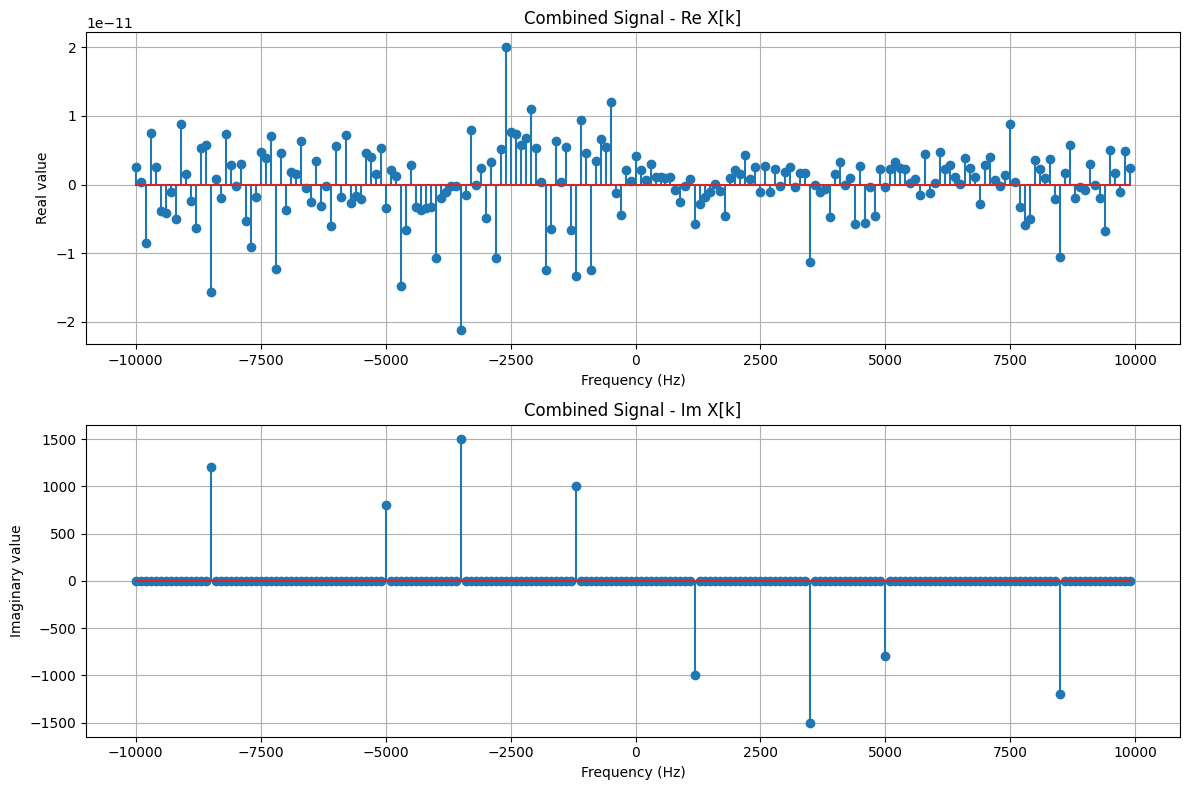

In [ ]:
combined_dft = calculate_dft(combined_signal)

combined_real = np.real(combined_dft)
combined_imag = np.imag(combined_dft)

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].stem(freq_bins[order], combined_real[order])
axes[0].set_title("Combined Signal - Re X[k]")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Real value")
axes[0].grid(True)

axes[1].stem(freq_bins[order], combined_imag[order])
axes[1].set_title("Combined Signal - Im X[k]")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Imaginary value")
axes[1].grid(True)

plt.tight_layout()
plt.show()

3. Then, compare it with the summed signals. (Part 1 Step 4)


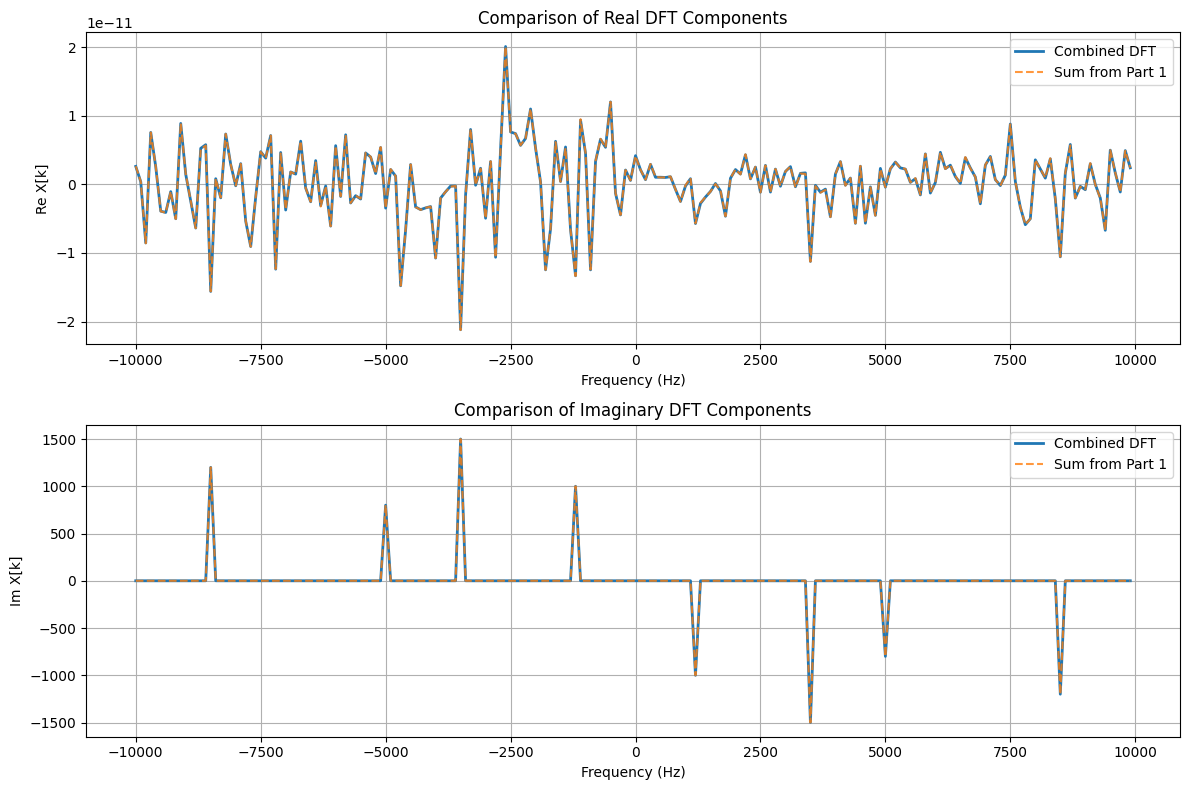

Maximum real-component difference: 2.8345098216980054e-13
Maximum imaginary-component difference: 5.55876261769123e-13


In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].plot(
    freq_bins[order], combined_real[order],
    label="Combined DFT", linewidth=2
)
axes[0].plot(
    freq_bins[order], sum_real[order],
    "--", label="Sum from Part 1", alpha=0.8
)
axes[0].set_title("Comparison of Real DFT Components")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Re X[k]")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    freq_bins[order], combined_imag[order],
    label="Combined DFT", linewidth=2
)
axes[1].plot(
    freq_bins[order], sum_imag[order],
    "--", label="Sum from Part 1", alpha=0.8
)
axes[1].set_title("Comparison of Imaginary DFT Components")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Im X[k]")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("Maximum real-component difference:",
      np.max(np.abs(combined_real - sum_real)))

print("Maximum imaginary-component difference:",
      np.max(np.abs(combined_imag - sum_imag)))

4. Compute the Mag X[k] and Phase X[k] of the combined signal as well.


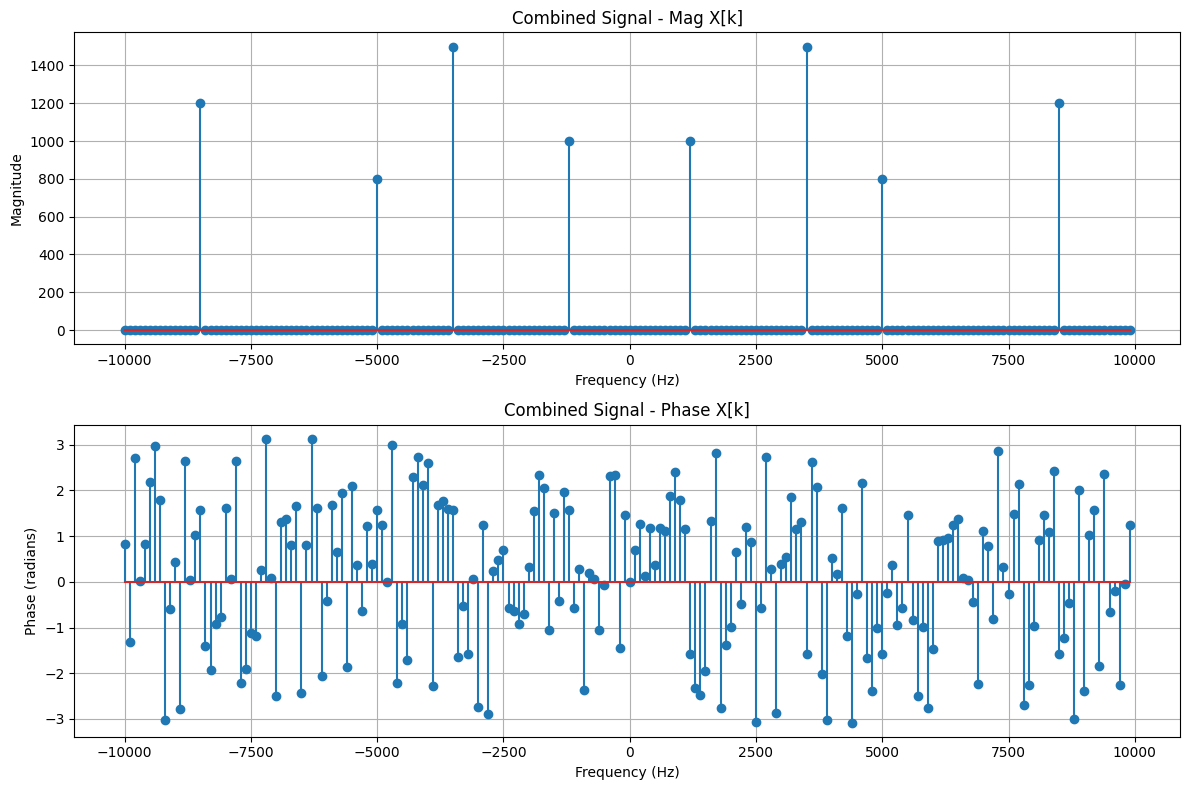

In [ ]:
combined_magnitude = np.abs(combined_dft)
combined_phase = np.angle(combined_dft)

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].stem(freq_bins[order], combined_magnitude[order])
axes[0].set_title("Combined Signal - Mag X[k]")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Magnitude")
axes[0].grid(True)

axes[1].stem(freq_bins[order], combined_phase[order])
axes[1].set_title("Combined Signal - Phase X[k]")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Phase (radians)")
axes[1].grid(True)

plt.tight_layout()
plt.show()

5. Then, compare it with the summed signals. (Part 1 Step 5)


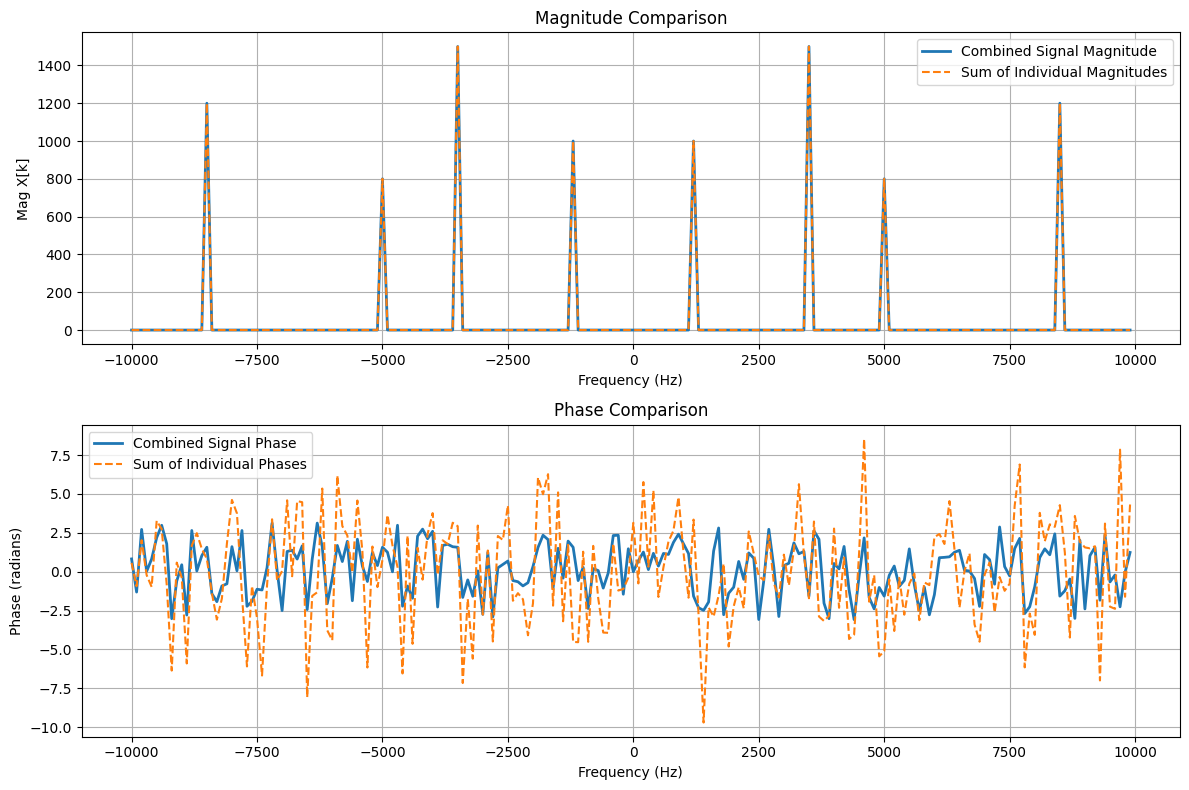

Maximum magnitude difference: 3.7971403799019754e-11
Maximum phase difference: 10.101524035557876


In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# Compare magnitude
axes[0].plot(
    freq_bins[order],
    combined_magnitude[order],
    label="Combined Signal Magnitude",
    linewidth=2
)
axes[0].plot(
    freq_bins[order],
    sum_magnitude[order],
    "--",
    label="Sum of Individual Magnitudes"
)
axes[0].set_title("Magnitude Comparison")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Mag X[k]")
axes[0].legend()
axes[0].grid(True)

# Compare phase
axes[1].plot(
    freq_bins[order],
    combined_phase[order],
    label="Combined Signal Phase",
    linewidth=2
)
axes[1].plot(
    freq_bins[order],
    sum_phase[order],
    "--",
    label="Sum of Individual Phases"
)
axes[1].set_title("Phase Comparison")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Phase (radians)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("Maximum magnitude difference:",
      np.max(np.abs(combined_magnitude - sum_magnitude)))

print("Maximum phase difference:",
      np.max(np.abs(combined_phase - sum_phase)))